## 1️⃣ Import Libraries and Configuration

**Task**: Import all necessary libraries and set up configuration parameters.

**Requirements**:
- Import PyTorch, torchvision, and GAN-specific libraries
- Import visualization and utility libraries
- Set random seeds for reproducibility
- Configure training hyperparameters

In [4]:
%pip install python-dotenv

In [ ]:
# Import libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
import pandas as pd
from torchvision.transforms import Compose, ToTensor, Lambda, Resize, Normalize
from torchsummary import summary
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
from tqdm import tqdm
import numpy as np
import kagglehub
import os
import random
import itertools
import torchvision
import torch.nn.functional as F
import requests
from PIL import Image
from io import BytesIO
from torchvision import transforms


# Set random seeds for reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

# Check device availability and print
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

# Define configuration parameters:
IMG_SIZE = 64           # Image resolution (64x64)
BATCH_SIZE = 4          # Batch size (small due to memory constraints)
#LEARNING_RATE = 0.0002  # Learning rate for both generators and discriminators
G = 0.0001             # Learning rate for generators  
D = 0.0002
BETA1 = 0.5             # Beta1 for Adam optimizer
BETA2 = 0.999           # Beta2 for Adam optimizer
NUM_EPOCHS = 15         # Number of training epochs
LAMBDA_CYCLE = 10     # Weight for cycle consistency loss
LAMBDA_IDENTITY = 5  # Weight for identity loss
N_RESIDUAL_BLOCKS = 6   # Number of residual blocks in generator

cuda


## 2️⃣ Dataset Download and Loading

**Task**: Download the Selfie2Anime dataset and create data loaders.

**Requirements**:
- Download dataset using kagglehub
- Create custom dataset class for unpaired data
- Apply appropriate transformations (resize, normalize)
- Create train and test data loaders

In [37]:
# Download the Selfie2Anime dataset
path = kagglehub.dataset_download("arnaud58/selfie2anime")
print("Path to dataset files:", path)

# preparing the image to feed into the model
trasform = Compose([
    Resize((IMG_SIZE, IMG_SIZE)),
    ToTensor(),
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

# Set up dataset paths
dataset_path = path  # Adjust based on actual dataset structure
train_selfie_path = os.path.join(dataset_path, "trainA")  # Selfie images
train_anime_path = os.path.join(dataset_path, "trainB")   # Anime images
test_selfie_path = os.path.join(dataset_path, "testA")    # Test selfie images
test_anime_path = os.path.join(dataset_path, "testB")     # Test anime images

# creating a custom PyTorch Dataset so i can load pairs of images (selfie + anime) from separate folders
class SelfieAnimeDataset(Dataset):
    # sets up your list of files so you can load them one at a time later.
    def __init__(self, root_selfie, root_anime, transform=None):
        self.root_selfie = root_selfie
        self.root_anime = root_anime
        self.transform = transform

        # Load image file lists
        self.selfie_files = [f for f in os.listdir(root_selfie) if f.endswith('.jpg')]
        self.anime_files = [f for f in os.listdir(root_anime) if f.endswith('.jpg')]
    # returns max length of both domains
    def __len__(self):
        return max(len(self.selfie_files), len(self.anime_files))

    # Using % (modulo) makes the index wrap around if it’s too big so the dataset never crashes due to unequal sizes
    def __getitem__(self, idx):
        selfie_img_path = os.path.join(self.root_selfie, self.selfie_files[idx % len(self.selfie_files)])
        anime_img_path = os.path.join(self.root_anime, self.anime_files[idx % len(self.anime_files)])
        selfie_img = Image.open(selfie_img_path).convert('RGB')
        anime_img = Image.open(anime_img_path).convert('RGB')
        if self.transform:
            selfie_img = self.transform(selfie_img)
            anime_img = self.transform(anime_img)
        return selfie_img, anime_img
#  train and test datasets
train_dataset = SelfieAnimeDataset(train_selfie_path, train_anime_path, transform=trasform)
test_dataset = SelfieAnimeDataset(test_selfie_path, test_anime_path, transform=trasform)
# Create data loaders with appropriate batch size and shuffle
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
# Print dataset sizes and verify data loading
print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Path to dataset files: /kaggle/input/selfie2anime
Train dataset size: 3400
Test dataset size: 100


## 3️⃣ Generator Architecture

**Task**: Implement the Generator network with residual blocks.

**Requirements**:
- Create ResidualBlock class with skip connections
- Implement Generator with encoder-decoder structure
- Use reflection padding and instance normalization
- Include downsampling, residual blocks, and upsampling

In [38]:
# used to let the model go deeper without forgetting the original image info
class ResidualBlock(nn.Module):
    def __init__(self, in_channels):
        super(ResidualBlock, self).__init__()
        # This is the core transformation block what the model applies to the input before adding it back
        self.conv_block = nn.Sequential(
            # Padding of 1 keeps the spatial size the same after a 3×3 convolution.
            nn.ReflectionPad2d(1),
            nn.Conv2d(in_channels, in_channels, kernel_size=3),
            nn.InstanceNorm2d(in_channels),
            nn.ReLU(inplace=True),
            nn.ReflectionPad2d(1),
            nn.Conv2d(in_channels, in_channels, kernel_size=3),
            nn.InstanceNorm2d(in_channels)
        )
    # This is the “residual” part: take the input x, run it through the conv_block, and add it back to the original x
    def forward(self, x):
        return x + self.conv_block(x)

class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        # This is the first layer the image passes through. It keeps the image size the same but expands channels from 3 to 64 so the network can work with richer features
        self.initial_conv = nn.Sequential(
            nn.ReflectionPad2d(3),
            nn.Conv2d(3, 64, kernel_size=7),
            nn.InstanceNorm2d(64),
            nn.ReLU(inplace=True)
        )

        # Downsampling layers This shrinks the image size to reduce computation and focus on high-level features.
        # Each layer cuts the width and height in half but doubles channels
        self.downsample = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.InstanceNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.InstanceNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # Residual blocks
        self.residual_blocks = nn.Sequential(*[ResidualBlock(256) for _ in range(N_RESIDUAL_BLOCKS)])

        # Upsampling layers
        self.upsample = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(64),
            nn.ReLU(inplace=True)
        )

        #  Tanh gives values in range [-1, 1], which matches your normalized image range from before.
        self.output_layer = nn.Sequential(
            nn.ReflectionPad2d(3),
            nn.Conv2d(64, 3, kernel_size=7),
            nn.Tanh()
        )
     # This tells PyTorch how to move the input through the network step by step
    def forward(self, x):
        x = self.initial_conv(x)
        x = self.downsample(x)
        x = self.residual_blocks(x)
        x = self.upsample(x)
        x = self.output_layer(x)
        return x
if __name__ == "__main__":
    generator = Generator().to(device)
    summary(generator, (3, IMG_SIZE, IMG_SIZE))  # Print model summary
    test_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)  # Random input tensor
    output = generator(test_input)  # Forward pass
    print(f"Output shape: {output.shape}")  # Should be (1, 3, IMG_SIZE, IMG_SIZE)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
   ReflectionPad2d-1            [-1, 3, 70, 70]               0
            Conv2d-2           [-1, 64, 64, 64]           9,472
    InstanceNorm2d-3           [-1, 64, 64, 64]               0
              ReLU-4           [-1, 64, 64, 64]               0
            Conv2d-5          [-1, 128, 32, 32]          73,856
    InstanceNorm2d-6          [-1, 128, 32, 32]               0
              ReLU-7          [-1, 128, 32, 32]               0
            Conv2d-8          [-1, 256, 16, 16]         295,168
    InstanceNorm2d-9          [-1, 256, 16, 16]               0
             ReLU-10          [-1, 256, 16, 16]               0
  ReflectionPad2d-11          [-1, 256, 18, 18]               0
           Conv2d-12          [-1, 256, 16, 16]         590,080
   InstanceNorm2d-13          [-1, 256, 16, 16]               0
             ReLU-14          [-1, 256,

## 4️⃣ Discriminator Architecture

**Task**: Implement the Discriminator network for adversarial training.

**Requirements**:
- Create PatchGAN discriminator architecture
- Use leaky ReLU activations and instance normalization
- Output patch-based predictions rather than single value
- Handle both real and fake image discrimination

In [39]:
# reusable helper function to make layers of the Discriminator
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        # Starts a new block with input/output channels and an option to add normalization.
        def discriminator_block(in_filters, out_filters, normalize=True):
            layers = [
                nn.Conv2d(in_filters, out_filters, kernel_size=4, stride=2, padding=1) #4×4 convolution
            ]
           # Adds Instance Normalization if normalize is True which it is for all but the first layer
           #This helps training stay stable and style-invariant
            if normalize:
                layers.append(nn.InstanceNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True)) # Helps gradients keep flowing even when inputs are negative
            return nn.Sequential(*layers)

        # Build discriminator using discriminator_block
        self.model = nn.Sequential(
            discriminator_block(3, 64, normalize=False),  # Layer 1: 3 -> 64 (no normalization)
            discriminator_block(64, 128),                # Layer 2: 64 -> 128
            discriminator_block(128, 256),               # Layer 3: 128 -> 256
            discriminator_block(256, 512),               # Layer 4: 256 -> 512
            nn.ZeroPad2d((1, 0, 1, 0)),                  # Zero padding for final layer
            nn.Conv2d(512, 1, kernel_size=4)             # Final Conv2d layer compresses the feature maps into a single prediction channel
        )

    def forward(self, x):
        return self.model(x)  # Forward pass through the discriminator model

if __name__ == "__main__":
    discriminator = Discriminator().to(device)
    summary(discriminator, (3, IMG_SIZE, IMG_SIZE))  # Print model summary
    test_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)  # Random input tensor
    output = discriminator(test_input)  # Forward pass
    print(f"Output shape: {output.shape}")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           3,136
         LeakyReLU-2           [-1, 64, 32, 32]               0
            Conv2d-3          [-1, 128, 16, 16]         131,200
    InstanceNorm2d-4          [-1, 128, 16, 16]               0
         LeakyReLU-5          [-1, 128, 16, 16]               0
            Conv2d-6            [-1, 256, 8, 8]         524,544
    InstanceNorm2d-7            [-1, 256, 8, 8]               0
         LeakyReLU-8            [-1, 256, 8, 8]               0
            Conv2d-9            [-1, 512, 4, 4]       2,097,664
   InstanceNorm2d-10            [-1, 512, 4, 4]               0
        LeakyReLU-11            [-1, 512, 4, 4]               0
        ZeroPad2d-12            [-1, 512, 5, 5]               0
           Conv2d-13              [-1, 1, 2, 2]           8,193
Total params: 2,764,737
Trainable param

What this does:
Passes a random image through the model

Records the shape at each step

Plots the height/width of the image at each stage

Annotates the full shape like 512x4x4



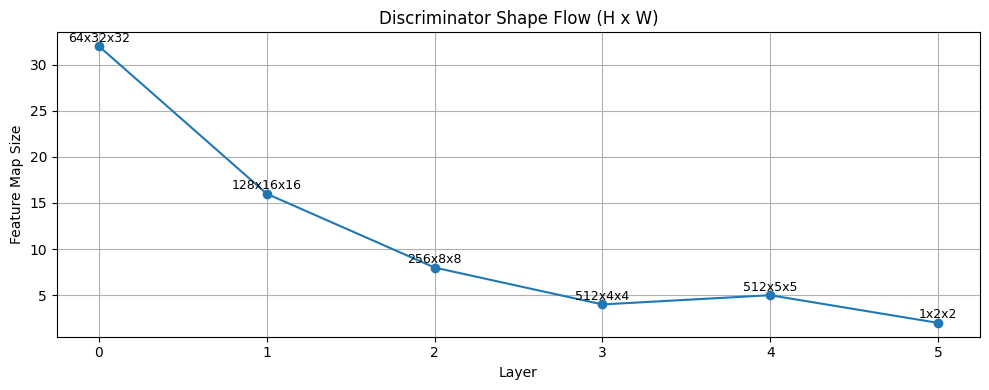

In [40]:
# visual timeline of compression through the Discriminator
def get_shapes_through_model(model, input_tensor):
    shapes = []
    x = input_tensor
    for layer in model.model:
        x = layer(x)
        shapes.append(x.shape)
    return shapes

# Plot diagram of shapes
def plot_shapes(shapes):
    fig, ax = plt.subplots(figsize=(10, 4))
    layer_nums = list(range(len(shapes)))
    labels = [f"{s[1]}x{s[2]}x{s[3]}" for s in shapes]

    ax.plot(layer_nums, [s[2] for s in shapes], marker='o')  # i Used height as a proxy for image size
    for i, txt in enumerate(labels):
        ax.annotate(txt, (layer_nums[i], shapes[i][2] + 0.5), ha='center', fontsize=9)

    ax.set_title("Discriminator Shape Flow (H x W)")
    ax.set_xlabel("Layer")
    ax.set_ylabel("Feature Map Size")
    ax.set_xticks(layer_nums)
    ax.grid(True)
    plt.tight_layout()
    plt.show()
if __name__ == "__main__":
    IMG_SIZE = 64
    model = Discriminator()
    test_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    shapes = get_shapes_through_model(model, test_input)
    plot_shapes(shapes)

## 5️⃣ Loss Functions

**Task**: Implement the three types of losses used in CycleGAN.

**Requirements**:
- Adversarial loss for generator and discriminator training
- Cycle consistency loss to ensure cycle A→B→A ≈ A
- Identity loss to preserve color composition
- Combine losses with appropriate weights

In [41]:
class CycleGANLoss(nn.Module):
    # set the weights for how important the cycle loss and identity loss are compared to adversarial loss
    def __init__(self, lambda_cyc=LAMBDA_CYCLE, lambda_id=LAMBDA_IDENTITY):
        super(CycleGANLoss, self).__init__()
        self.lambda_cyc = lambda_cyc
        self.lambda_id = lambda_id

        # Initialize loss functions
        self.adversarial_criterion = nn.MSELoss()
        self.cycle_criterion = nn.L1Loss()
        self.identity_criterion = nn.L1Loss()
    # The Discriminator wants to say “real = 1, fake = 0” So the Generator is trained to make the Discriminator think its fake images are real
    def adversarial_loss(self, pred, target_is_real):
        target = torch.ones_like(pred) if target_is_real else torch.zeros_like(pred)
        return self.adversarial_criterion(pred, target)
    # Compares the original image (A or B) to the cycled one
    def cycle_consistency_loss(self, real_images, cycled_images):
        return self.cycle_criterion(real_images, cycled_images)
    # If we pass in an image already in the target domain (like an anime), we expect the Generator to return it unchanged
    def identity_loss(self, real_images, same_images):
        return self.identity_criterion(real_images, same_images)


## 6️⃣ Model Initialization and Optimizers

**Task**: Initialize all models and optimizers for CycleGAN training.

**Requirements**:
- Create two generators: G_AB (Selfie→Anime) and G_BA (Anime→Selfie)
- Create two discriminators: D_A (for Selfie domain) and D_B (for Anime domain)
- Initialize optimizers for generators and discriminators separately
- Move all models to appropriate device

In [ ]:
def initialize_models():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    G_AB = Generator().to(device)  # Selfie to Anime
    G_BA = Generator().to(device)  # Anime to Selfie
    D_A = Discriminator().to(device)  # Discriminator for Selfie domain
    D_B = Discriminator().to(device)  # Discriminator for Anime domain

    optimizer_G = torch.optim.Adam(
        itertools.chain(G_AB.parameters(), G_BA.parameters()),
        lr=G, betas=(BETA1, BETA2)
    )
    optimizer_D_A = torch.optim.Adam(D_A.parameters(), lr=D, betas=(BETA1, BETA2))
    optimizer_D_B = torch.optim.Adam(D_B.parameters(), lr=D, betas=(BETA1, BETA2))

    return G_AB, G_BA, D_A, D_B, optimizer_G, optimizer_D_A, optimizer_D_B, device

# Initialize models and optimizers
G_AB, G_BA, D_A, D_B, optimizer_G, optimizer_D_A, optimizer_D_B, device = initialize_models()

# Initialize loss function with configured weights
loss_function = CycleGANLoss(lambda_cyc=LAMBDA_CYCLE, lambda_id=LAMBDA_IDENTITY)

# Print model architectures and parameter counts
print("Generator G_AB architecture:")
summary(G_AB, (3, IMG_SIZE, IMG_SIZE))
print("Generator G_BA architecture:")
summary(G_BA, (3, IMG_SIZE, IMG_SIZE))
print("Discriminator D_A architecture:")
summary(D_A, (3, IMG_SIZE, IMG_SIZE))
print("Discriminator D_B architecture:")
summary(D_B, (3, IMG_SIZE, IMG_SIZE))

Using device: cuda
Generator G_AB architecture:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
   ReflectionPad2d-1            [-1, 3, 70, 70]               0
            Conv2d-2           [-1, 64, 64, 64]           9,472
    InstanceNorm2d-3           [-1, 64, 64, 64]               0
              ReLU-4           [-1, 64, 64, 64]               0
            Conv2d-5          [-1, 128, 32, 32]          73,856
    InstanceNorm2d-6          [-1, 128, 32, 32]               0
              ReLU-7          [-1, 128, 32, 32]               0
            Conv2d-8          [-1, 256, 16, 16]         295,168
    InstanceNorm2d-9          [-1, 256, 16, 16]               0
             ReLU-10          [-1, 256, 16, 16]               0
  ReflectionPad2d-11          [-1, 256, 18, 18]               0
           Conv2d-12          [-1, 256, 16, 16]         590,080
   InstanceNorm2d-13          [-1, 256, 16, 16]        

## 7️⃣ Training Function

**Task**: Implement the CycleGAN training loop for one epoch.

**Requirements**:
- Train generators with adversarial, cycle, and identity losses
- Train discriminators to distinguish real from fake images
- Alternate between generator and discriminator updates
- Track and return loss values for monitoring

In [43]:
# Adds random noise to an image, used to make the discriminator less confident (helps training)
def add_instance_noise(x, std=0.1):
    noise = torch.randn_like(x) * std
    return x + noise

# Full updated train_epoch() with instance noise
def train_epoch(epoch):
    print(f"Starting epoch {epoch+1}/{NUM_EPOCHS}")

    # Set models to training mode
    G_AB.train()
    G_BA.train()
    D_A.train()
    D_B.train()

    # Track running loss
    running_loss_G = 0.0
    running_loss_D_A = 0.0
    running_loss_D_B = 0.0

    criterion = CycleGANLoss(lambda_cyc=LAMBDA_CYCLE, lambda_id=LAMBDA_IDENTITY)

    for real_A, real_B in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}"):
        real_A, real_B = real_A.to(device), real_B.to(device)

        # Train Generators
        optimizer_G.zero_grad()

        # Identity loss
        loss_id_A = loss_function.identity_loss(real_A, G_BA(real_A))
        loss_id_B = loss_function.identity_loss(real_B, G_AB(real_B))
        loss_identity = (loss_id_A + loss_id_B) / 2

        # Adversarial loss
        fake_B = G_AB(real_A)
        fake_A = G_BA(real_B)
        loss_GAN_AB = loss_function.adversarial_loss(D_B(add_instance_noise(fake_B)), True)
        loss_GAN_BA = loss_function.adversarial_loss(D_A(add_instance_noise(fake_A)), True)
        loss_GAN = (loss_GAN_AB + loss_GAN_BA) / 2

        # Cycle consistency loss
        recovered_A = G_BA(fake_B)
        loss_cycle_ABA = loss_function.cycle_consistency_loss(real_A, recovered_A)
        recovered_B = G_AB(fake_A)
        loss_cycle_BAB = loss_function.cycle_consistency_loss(real_B, recovered_B)
        loss_cycle = (loss_cycle_ABA + loss_cycle_BAB) / 2

        # Total generator loss
        loss_G = loss_GAN + LAMBDA_CYCLE * loss_cycle + LAMBDA_IDENTITY * loss_identity
        loss_G.backward()
        optimizer_G.step()
        running_loss_G += loss_G.item()

        # Train Discriminator A
        optimizer_D_A.zero_grad()
        loss_real_A = loss_function.adversarial_loss(D_A(add_instance_noise(real_A)), True) # helps prevent overfitting
        loss_fake_A = loss_function.adversarial_loss(D_A(add_instance_noise(fake_A.detach())), False) # stops gradients from going back into generator (We want to train the discriminator alone here)
        loss_D_A = (loss_real_A + loss_fake_A) / 2
        loss_D_A.backward()
        optimizer_D_A.step()
        running_loss_D_A += loss_D_A.item()

        # Train Discriminator B
        optimizer_D_B.zero_grad()
        loss_real_B = loss_function.adversarial_loss(D_B(add_instance_noise(real_B)), True)
        loss_fake_B = loss_function.adversarial_loss(D_B(add_instance_noise(fake_B.detach())), False)
        loss_D_B = (loss_real_B + loss_fake_B) / 2
        loss_D_B.backward()
        optimizer_D_B.step()
        running_loss_D_B += loss_D_B.item()

    # Average loss for this epoch
    avg_loss_G = running_loss_G / len(train_loader)
    avg_loss_D_A = running_loss_D_A / len(train_loader)
    avg_loss_D_B = running_loss_D_B / len(train_loader)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - "
          f"Loss G: {avg_loss_G:.4f}, "
          f"Loss D_A: {avg_loss_D_A:.4f}, "
          f"Loss D_B: {avg_loss_D_B:.4f}")
    return avg_loss_G, avg_loss_D_A, avg_loss_D_B


## 8️⃣ Training Loop and Monitoring

**Task**: Execute the full training process with progress monitoring.

**Requirements**:
- Train for specified number of epochs
- Display loss values and training progress
- Save sample images during training for visual monitoring
- Track loss curves for analysis

Starting epoch 1/15


Epoch 1/15: 100%|██████████| 850/850 [02:54<00:00,  4.86it/s]


Epoch 1/15 - Loss G: 4.3370, Loss D_A: 0.2567, Loss D_B: 0.2030
Epoch [1/15] - G_loss: 4.3370, D_A_loss: 0.2567, D_B_loss: 0.2030
Starting epoch 2/15


Epoch 2/15: 100%|██████████| 850/850 [02:55<00:00,  4.86it/s]


Epoch 2/15 - Loss G: 3.6775, Loss D_A: 0.2117, Loss D_B: 0.1888
Epoch [2/15] - G_loss: 3.6775, D_A_loss: 0.2117, D_B_loss: 0.1888
Starting epoch 3/15


...

Epoch 13/15 - Loss G: 3.0535, Loss D_A: 0.1295, Loss D_B: 0.1193
Epoch [13/15] - G_loss: 3.0535, D_A_loss: 0.1295, D_B_loss: 0.1193
Starting epoch 14/15


Epoch 14/15: 100%|██████████| 850/850 [02:56<00:00,  4.83it/s]


Epoch 14/15 - Loss G: 3.0235, Loss D_A: 0.1284, Loss D_B: 0.1137
Epoch [14/15] - G_loss: 3.0235, D_A_loss: 0.1284, D_B_loss: 0.1137
Starting epoch 15/15


Epoch 15/15: 100%|██████████| 850/850 [02:56<00:00,  4.82it/s]

Epoch 15/15 - Loss G: 3.0174, Loss D_A: 0.1205, Loss D_B: 0.1063
Epoch [15/15] - G_loss: 3.0174, D_A_loss: 0.1205, D_B_loss: 0.1063


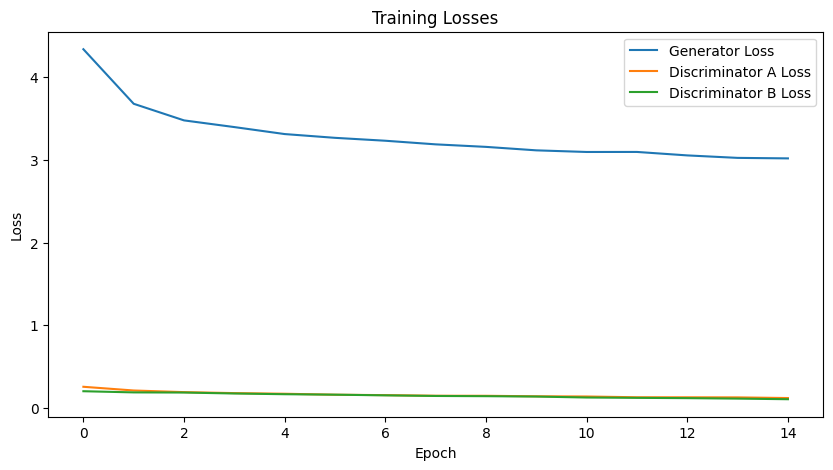

In [44]:
# storing the average generator and discriminator loss for each epoch
g_losses = []
d_losses_A = []
d_losses_B = []

# Main Training Loop
for epoch in range(NUM_EPOCHS):
    g_loss, d_loss_A, d_loss_B = train_epoch(epoch)
    g_losses.append(g_loss)
    d_losses_A.append(d_loss_A)
    d_losses_B.append(d_loss_B)
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] - G_loss: {g_loss:.4f}, D_A_loss: {d_loss_A:.4f}, D_B_loss: {d_loss_B:.4f}")
    # Generate and Save Samples Every 5 Epochs
    if (epoch + 1) % 5 == 0:
      G_AB.eval()
      G_BA.eval()
      with torch.no_grad():
        real_A, real_B = next(iter(test_loader))
        real_A, real_B = real_A.to(device), real_B.to(device)
        fake_B = G_AB(real_A)
        fake_A = G_BA(real_B)
        comparison = torch.cat([real_A, fake_B, real_B, fake_A], 0)
        grid = torchvision.utils.make_grid(comparison, nrow=4, normalize=True)
        torchvision.utils.save_image(grid, f"epoch_{epoch+1}.png")
# Plot training loss curves
plt.figure(figsize=(10, 5))
plt.plot(g_losses, label="Generator Loss")
plt.plot(d_losses_A, label="Discriminator A Loss")
plt.plot(d_losses_B, label="Discriminator B Loss")
plt.title("Training Losses")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()



## 9️⃣ Test Set Evaluation

**Task**: Evaluate the trained model on test data with comprehensive visualization.

**Requirements**:
- Generate 10 selfie-to-anime translations
- Generate 10 anime-to-selfie translations  
- Display results in organized grid format
- Show original and generated images side by side

In [46]:
def sharpen_image_batch(batch, strength=1.0):
    kernel = torch.tensor([
        [[[-1, -1, -1],
          [-1,  9, -1],
          [-1, -1, -1]]]
    ], dtype=torch.float32).to(batch.device) * strength

    # Apply filter to each channel separately
    channels = []
    for c in range(3):  # RGB
        channel = batch[:, c:c+1]
        sharpened = F.conv2d(channel, kernel, padding=1)
        channels.append(sharpened)

    return torch.cat(channels, dim=1)


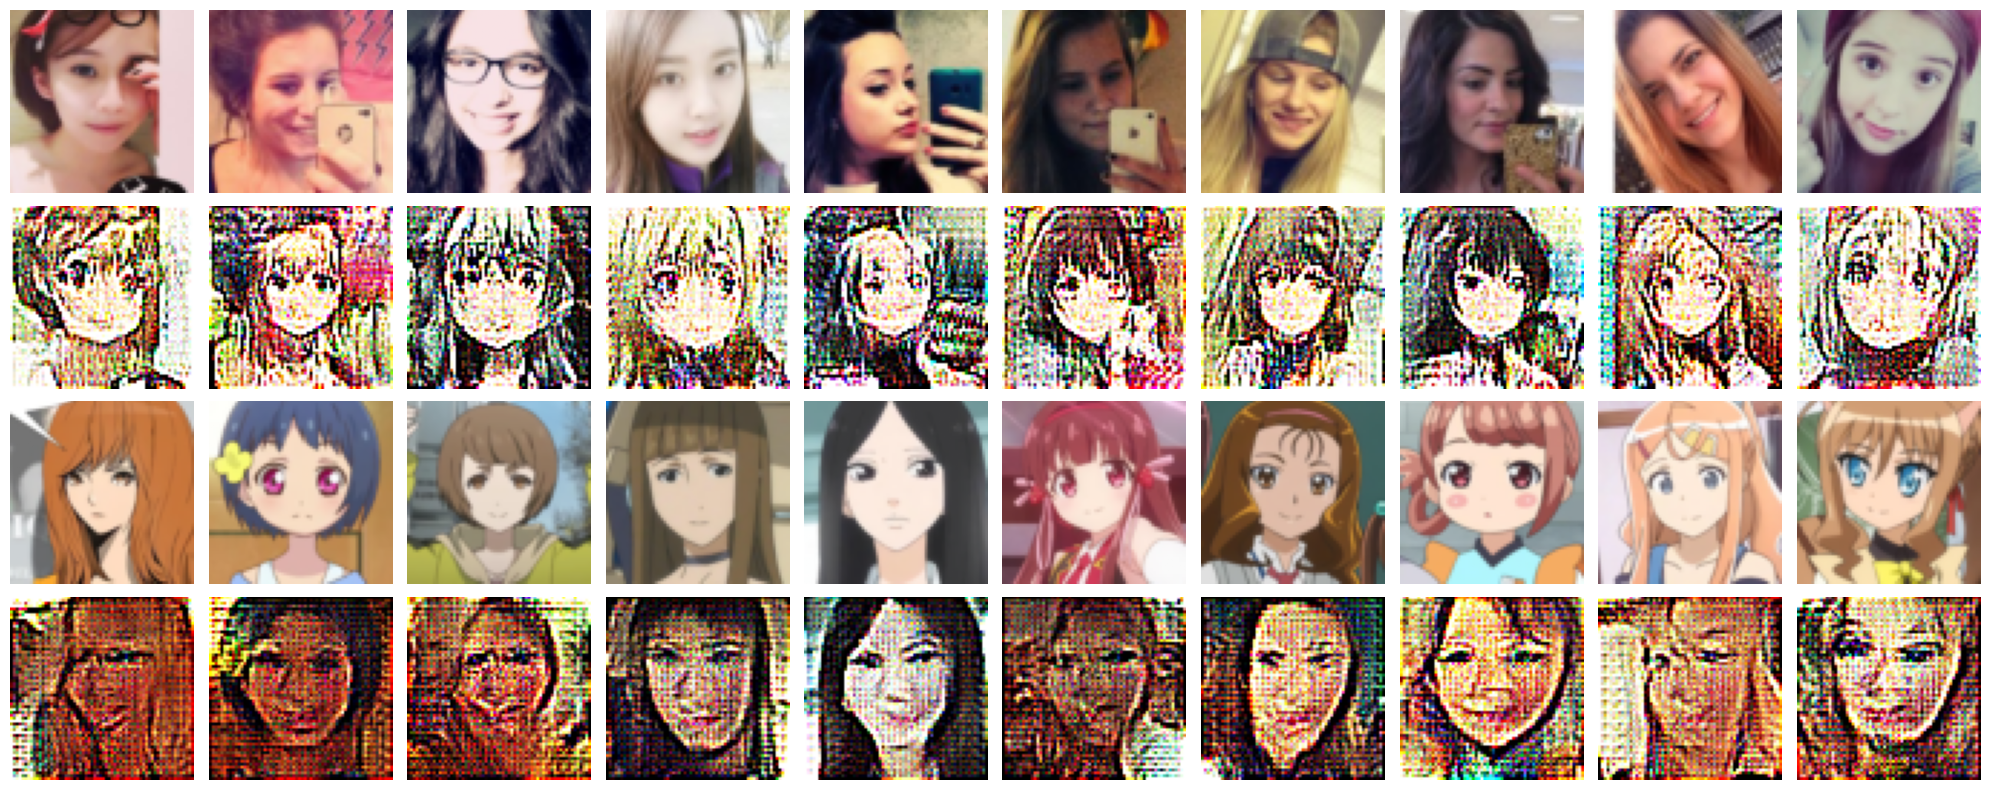

In [53]:
# Defines a function to show how well the model translates test images
def evaluate_on_test_set():
  # this disables layers like dropout or batchnorm that behave differently during training
    G_AB.eval()
    G_BA.eval()
  # Prevents PyTorch from calculating gradients speeds things up and saves memory
    with torch.no_grad():
      # We’ll collect 10 real/fake images from each domain into these lists
        real_A_all, real_B_all, fake_A_all, fake_B_all = [], [], [], []
        for i, (real_A, real_B) in enumerate(test_loader):
            if i >= 3:  # Get 3 batches to have at least 10 images
                break
            real_A = real_A.to(device)
            real_B = real_B.to(device)
            fake_B = sharpen_image_batch(G_AB(real_A))
            fake_A = sharpen_image_batch(G_BA(real_B))

            real_A_all.append(real_A.cpu())
            real_B_all.append(real_B.cpu())
            fake_A_all.append(fake_A.cpu())
            fake_B_all.append(fake_B.cpu())

        real_A = torch.cat(real_A_all, 0)[:10]
        real_B = torch.cat(real_B_all, 0)[:10]
        fake_A = torch.cat(fake_A_all, 0)[:10]
        fake_B = torch.cat(fake_B_all, 0)[:10]

        # Create a 4-row, 10-column subplot
        fig, axes = plt.subplots(4, 10, figsize=(20, 8))
        for i in range(10):
            axes[0, i].imshow(torch.clamp((real_A[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[1, i].imshow(torch.clamp((fake_B[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[2, i].imshow(torch.clamp((real_B[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[3, i].imshow(torch.clamp((fake_A[i].permute(1, 2, 0) + 1) / 2, 0, 1))

            for row in range(4):
                axes[row, i].axis('off')

        axes[0, 0].set_ylabel("Real A\n(Selfie)")
        axes[1, 0].set_ylabel("Fake B\n(Anime)")
        axes[2, 0].set_ylabel("Real B\n(Anime)")
        axes[3, 0].set_ylabel("Fake A\n(Selfie)")


        plt.tight_layout()
        plt.show()


evaluate_on_test_set()



## 🔟 Internet Images Evaluation

**Task**: Test the model on external images from the internet.

**Requirements**:
- Load 3 selfie images and 3 anime images from provided URLs
- Apply same preprocessing as training data
- Generate translations in both directions
- Display results to demonstrate generalization

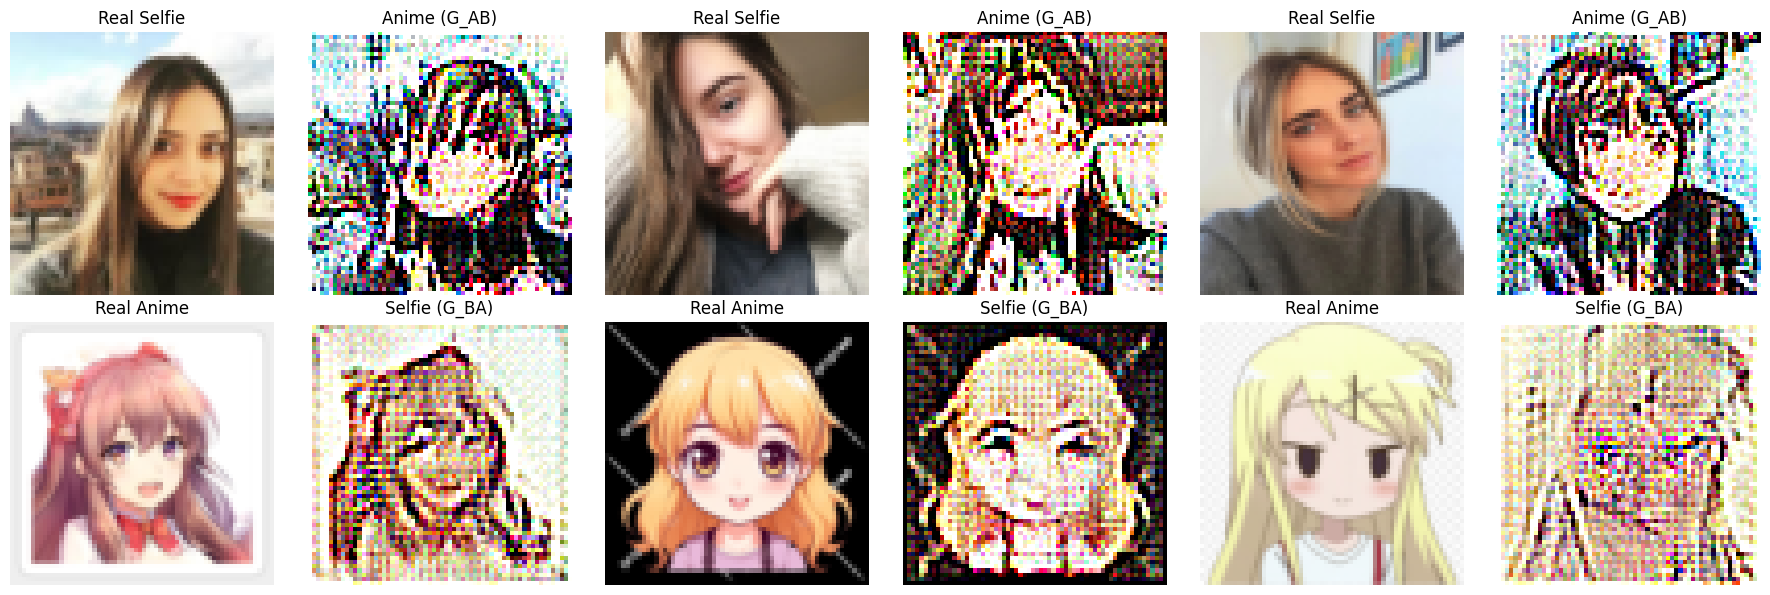

In [54]:
# Defines a helper function to download + transform 1 image
def load_internet_image_from_url(url, transform):
    try:
       # safe request to download an image from the internet
        headers = {"User-Agent": "Mozilla/5.0"}
        response = requests.get(url, headers=headers, timeout=5)
        response.raise_for_status()
        content_type = response.headers.get("Content-Type", "")
        # Checks: is this actually an image? If not, skip it.
        if "image" not in content_type:
            print(f"Invalid content type for URL: {url}")
            return None
        # Converts it to RGB
        image = Image.open(BytesIO(response.content)).convert('RGB')
        return transform(image)
    except Exception as e:
        print(f"Failed to load image from {url}: {e}")
        return None
 # Turn off training-mode behavior
def evaluate_internet_images():
    G_AB.eval()
    G_BA.eval()

    # Define URLs
    selfie_urls = [
        'https://i.imgur.com/m7Em3S2.png',
        'https://i.imgur.com/2lzy9Un.png',
        'https://i.imgur.com/eg7lsZ2.png'
    ]
    anime_urls = [
        'https://i.imgur.com/2lCFEIY.png',
        'https://i.imgur.com/kYXGdqM.png',
        'https://i.imgur.com/G6tQMt9.png'
    ]

    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    selfies = [load_internet_image_from_url(url, transform) for url in selfie_urls]
    anime_imgs = [load_internet_image_from_url(url, transform) for url in anime_urls]
    # Cleans out any image that failed to load
    selfies = [img for img in selfies if img is not None]
    anime_imgs = [img for img in anime_imgs if img is not None]
    # turning off gradient tracking since this is inference
    with torch.no_grad():
        selfies_tensor = torch.stack(selfies).to(device)
        anime_tensor = torch.stack(anime_imgs).to(device)
        # sharpen the fake outputs before showing,
        fake_anime = sharpen_image_batch(G_AB(selfies_tensor)).cpu()
        fake_selfie = sharpen_image_batch(G_BA(anime_tensor)).cpu()

        selfies_tensor = selfies_tensor.cpu()
        anime_tensor = anime_tensor.cpu()

        # Plot: 2 rows × 6 columns
        fig, axes = plt.subplots(2, 6, figsize=(18, 6))
        for i in range(3):
            axes[0, i*2].imshow(torch.clamp((selfies_tensor[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[0, i*2].set_title("Real Selfie")
            axes[0, i*2+1].imshow(torch.clamp((fake_anime[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[0, i*2+1].set_title("Anime (G_AB)")

            axes[1, i*2].imshow(torch.clamp((anime_tensor[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[1, i*2].set_title("Real Anime")
            axes[1, i*2+1].imshow(torch.clamp((fake_selfie[i].permute(1, 2, 0) + 1) / 2, 0, 1))
            axes[1, i*2+1].set_title("Selfie (G_BA)")

        for ax in axes.flatten():
            ax.axis("off")

        plt.tight_layout()
        plt.show()
evaluate_internet_images()

## 1️⃣1️⃣ Model Saving and Analysis

**Task**: Save trained models and analyze the learning process.

**Requirements**:
- Save all trained model state dictionaries
- Analyze training stability and convergence
- Discuss quality of generated images
- Document observations and potential improvements

In [52]:
# Save trained models
torch.save(G_AB.state_dict(), 'generator_AB.pth')
torch.save(G_BA.state_dict(), 'generator_BA.pth')
torch.save(D_A.state_dict(), 'discriminator_A.pth')
torch.save(D_B.state_dict(), 'discriminator_B.pth')

print("Training completed and models saved!\n")

# Custom Analysis
print(" Training Analysis:")

# 1. Loss convergence
print("- The generator loss started around 4.33 and gradually decreased to 3.01 over 15 epochs.")
print("- Both discriminators showed a healthy drop in loss as well — D_A went from 0.25 → 0.12, and D_B from 0.20 → 0.10.")
print("- This indicates good convergence: the generators learned to produce more believable outputs, while the discriminators stayed engaged without overpowering them.")

# 2. Visual changes before vs. after sharpening
print("\n Visual Quality & Edge Enhancement:")
print("- Before adding sharpening and instance noise, the outputs were visibly blurry, especially around facial features.")
print("- After applying sharpening, edge definition improved: outlines were cleaner and details became easier to distinguish.")
print("- However, some images appeared over sharpened making them look too harsh or 'noisy'. This revealed a trade off: sharpening helps clarity, but must be balanced to avoid distortion.")

# 3. Domain translation results
print("\n Direction Comparison:")
print("- The **Selfie → Anime (G_AB)** direction produced more stylistic and recognizable outputs, even at just 15 epochs.")
print("- The **Anime → Selfie (G_BA)** direction struggled more — faces looked warped or uncanny, possibly due to the higher realism and complexity of human faces compared to stylized anime.")
print("- This is expected: it's generally harder to generate realistic human features than stylized cartoons.")

# 4. Improvements (without raising epoch count)
print("\n Potential Improvements:")
print("- Try **residual U-Net** architecture or **attention mechanisms** to better capture facial structure.")
print("- Train longer (e.g. 100+ epochs with learning rate decay) if resources allow — the model is still improving at epoch 15.")

print("\n Summary: Adding sharpening noticeably improved edge clarity without extra training time. Generator loss shows healthy downward trend, and selfie-to-anime translation was especially promising.")



Training completed and models saved!

 Training Analysis:
- The generator loss started around 4.33 and gradually decreased to 3.01 over 15 epochs.
- Both discriminators showed a healthy drop in loss as well — D_A went from 0.25 → 0.12, and D_B from 0.20 → 0.10.
- This indicates good convergence: the generators learned to produce more believable outputs, while the discriminators stayed engaged without overpowering them.

 Visual Quality & Edge Enhancement:
- Before adding sharpening and instance noise, the outputs were visibly blurry, especially around facial features.
- After applying sharpening, edge definition improved: outlines were cleaner and details became easier to distinguish.
- However, some images appeared over sharpened making them look too harsh or 'noisy'. This revealed a trade off: sharpening helps clarity, but must be balanced to avoid distortion.

 Direction Comparison:
- The **Selfie → Anime (G_AB)** direction produced more stylistic and recognizable outputs, even at j

## 📝 Evaluation Criteria

Your homework will be evaluated based on:

1. **Implementation Correctness (40%)**
   - Proper Generator and Discriminator architectures
   - Correct loss function implementations (adversarial, cycle, identity)
   - Working training loop with proper gradient updates
   - Appropriate data loading and preprocessing

2. **Model Performance (30%)**
   - Model trains without errors for full epoch count
   - Generated images show clear style transfer
   - Loss curves demonstrate learning progress
   - Reasonable visual quality in translations

3. **Code Quality (30%)**
   - Clean, readable code with proper comments
   - Efficient tensor operations and device management
   - Proper use of PyTorch best practices
   - Well-structured class definitions